# HipMRI data inspection

Author: Angus Slater (s4961587). COMP3710 Pattern Recognition, The University of Queensland, 2026.

Explores one example scan (B040_Week0): label meanings, class balance, voxel spacing,
orientation, and what the model sees after 2x downsampling (Figure 2 in the README).
On Rangpur it reads the course copy in `/home/groups/comp3710/HipMRI_Study_open/`;
elsewhere it reads a local copy kept outside the repository at `~/Desktop/HipMRI_sample/`.
No scan files are stored in the repo.

In [ ]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from dataset import load_volume

# Data is never stored in the repo: use the course copy on Rangpur if available,
# otherwise a local copy of one scan kept outside the repo.
CASE = "B040_Week0"
ROOT = "/home/groups/comp3710/HipMRI_Study_open"
LOCAL = os.path.expanduser("~/Desktop/HipMRI_sample")
if os.path.isdir(ROOT):
    IMG = f"{ROOT}/semantic_MRs/{CASE}_LFOV.nii.gz"
    LAB = f"{ROOT}/semantic_labels_only/{CASE}_SEMANTIC.nii.gz"
else:
    IMG = f"{LOCAL}/{CASE}_LFOV.nii.gz"
    LAB = f"{LOCAL}/{CASE}_SEMANTIC.nii.gz"
print("Reading:", IMG)

img_nii = nib.load(IMG)
img = img_nii.get_fdata()
lab = nib.load(LAB).get_fdata().astype(int)
print("image shape:", img.shape, " label shape:", lab.shape)
os.makedirs("figures", exist_ok=True)
SAVE_FIGS = False   # set True only to regenerate the README figures

Reading: /Users/angusslater/Desktop/HipMRI_sample/B040_Week0_LFOV.nii.gz
image shape: (256, 256, 128)  label shape: (256, 256, 128)


## 1. What are the labels?

Views are centred on label 5. Comparing each label with the anatomy identifies them:
1 body, 2 bone, 3 bladder, 4 rectum, 5 prostate.

prostate centre voxel: 128 125 62
axial slices containing prostate: 51 to 73 of 128


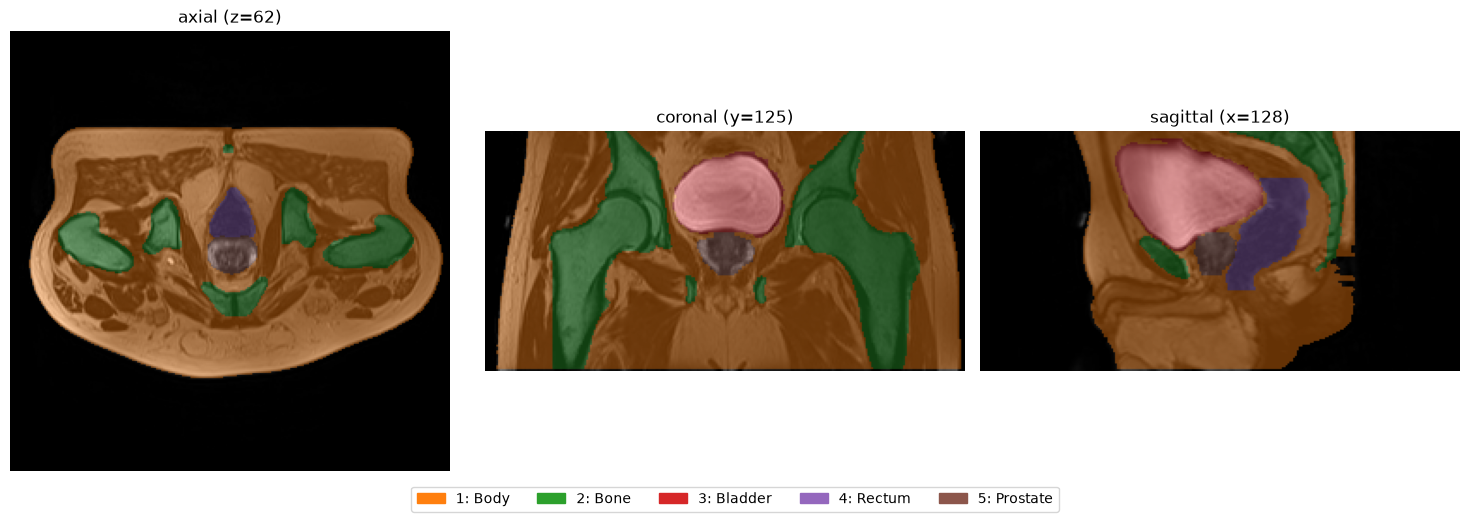

In [ ]:
LABELS = ["Background", "Body", "Bone", "Bladder", "Rectum", "Prostate"]

# Centre the views on label 5 (prostate)
vox = np.argwhere(lab == 5)
cx, cy, cz = vox.mean(0).astype(int)
print("prostate centre voxel:", cx, cy, cz)
print("axial slices containing prostate:", vox[:, 2].min(), "to", vox[:, 2].max(),
      "of", lab.shape[2])

views = [(img[:, :, cz], lab[:, :, cz], f"axial (z={cz})"),
         (img[:, cy, :], lab[:, cy, :], f"coronal (y={cy})"),
         (img[cx, :, :], lab[cx, :, :], f"sagittal (x={cx})")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (im, lb, title) in zip(axes, views):
    ax.imshow(im.T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_where(lb.T == 0, lb.T), cmap="tab10", vmin=0, vmax=9,
              alpha=0.4, origin="lower")
    ax.set_title(title)
    ax.axis("off")
cmap = plt.get_cmap("tab10")
fig.legend(handles=[Patch(color=cmap(k), label=f"{k}: {LABELS[k]}") for k in range(1, 6)],
           loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.06, 1, 1))
if SAVE_FIGS:
    plt.savefig("figures/data_example.png", dpi=120)
plt.show()

## 2. Class balance

The prostate is a tiny fraction of the volume, so plain cross-entropy would be dominated
by background. This motivates the Dice + CE loss.

In [3]:
values, counts = np.unique(lab, return_counts=True)
total = counts.sum()
print(f"Total voxels: {total:,} ({' x '.join(map(str, lab.shape))})")
for v, c in zip(values, counts):
    print(f"  {v} {LABELS[v]:<10} {c:>10,} voxels  {100 * c / total:6.2f}%")

Total voxels: 8,388,608 (256 x 256 x 128)
  0 Background  4,786,369 voxels   57.06%
  1 Body        3,100,645 voxels   36.96%
  2 Bone          325,181 voxels    3.88%
  3 Bladder       138,229 voxels    1.65%
  4 Rectum         30,023 voxels    0.36%
  5 Prostate        8,161 voxels    0.10%


## 3. Voxel spacing and orientation

Spacing decides the physical voxel size (needed for HD95 in mm); orientation decides which
array axis is left-right, front-back and foot-head (needed for the apex/base thirds).
Across all 211 scans (checked on Rangpur), in-plane spacing is 1.41–1.88 mm, slice spacing
1.56 mm, every scan is LPS, and one scan has 144 slices and is cropped to 128.

In [4]:
spacing = img_nii.header.get_zooms()
print("voxel spacing (mm):", tuple(round(float(s), 3) for s in spacing))
print("orientation:", nib.aff2axcodes(img_nii.affine))
print("voxel size after 2x downsampling (mm):", tuple(round(2 * float(s), 2) for s in spacing))

voxel spacing (mm): (1.562, 1.562, 1.56)
orientation: ('L', 'P', 'S')
voxel size after 2x downsampling (mm): (3.12, 3.12, 3.12)


## 4. What the model sees after downsampling

`load_volume()` from `dataset.py` crops to 128 slices, z-scores the image, and downsamples
2x (trilinear for the image, nearest for labels) to 128 x 128 x 64. This saves Figure 2.

downsampled: (1, 128, 128, 64) (128, 128, 64)  prostate voxels: 1020 (full res: 8161 )


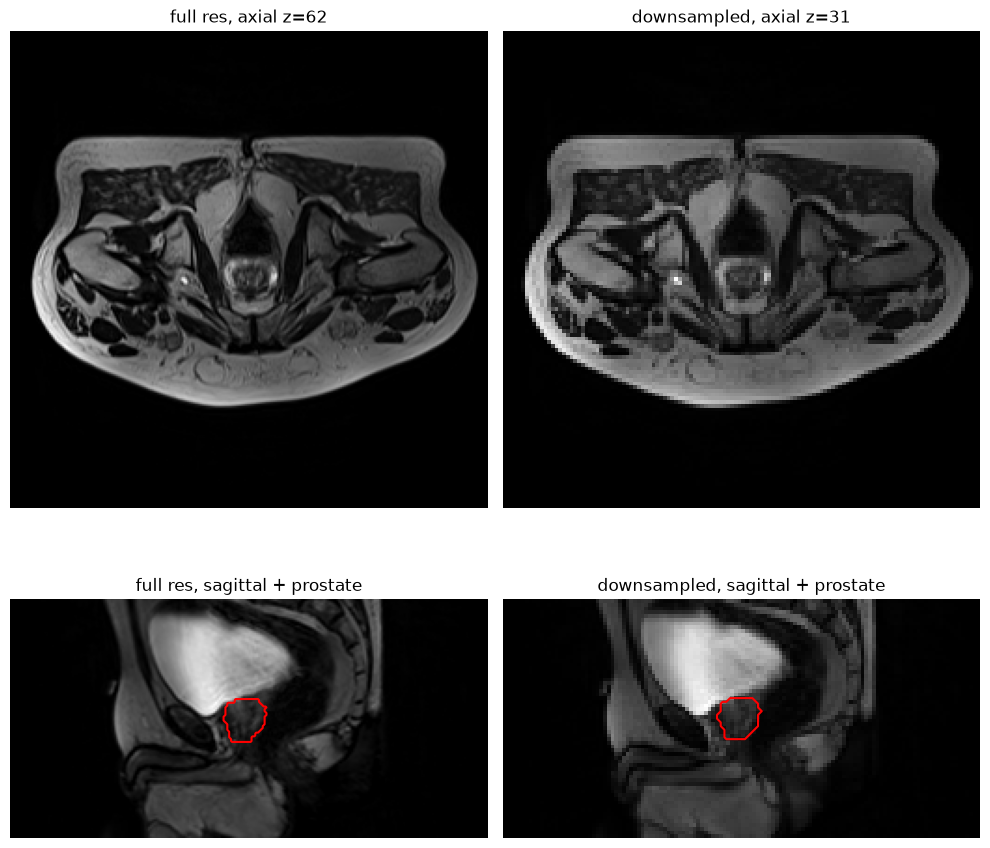

In [ ]:
img_ds, lab_ds = load_volume(IMG, LAB)
lab_full = lab
print("downsampled:", tuple(img_ds.shape), tuple(lab_ds.shape),
      " prostate voxels:", int((lab_ds == 5).sum()), "(full res:", int((lab_full == 5).sum()), ")")

# Prostate centre (cx, cy, cz) at full res -> halved after downsampling
fig, ax = plt.subplots(2, 2, figsize=(10, 10))
ax[0, 0].imshow(img[:, :, cz].T, cmap="gray", origin="lower")
ax[0, 0].set_title(f"full res, axial z={cz}")
ax[0, 1].imshow(img_ds[0, :, :, cz // 2].T, cmap="gray", origin="lower")
ax[0, 1].set_title(f"downsampled, axial z={cz // 2}")
ax[1, 0].imshow(img[cx, :, :].T, cmap="gray", origin="lower")
ax[1, 0].contour(lab_full[cx, :, :].T == 5, colors="r", origin="lower")
ax[1, 0].set_title("full res, sagittal + prostate")
ax[1, 1].imshow(img_ds[0, cx // 2, :, :].T, cmap="gray", origin="lower")
ax[1, 1].contour(lab_ds[cx // 2, :, :].T == 5, colors="r", origin="lower")
ax[1, 1].set_title("downsampled, sagittal + prostate")
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig("figures/downsample_check.png", dpi=120)
plt.show()

## Summary

- Labels: 0 background, 1 body, 2 bone, 3 bladder, 4 rectum, 5 prostate (~0.1% of voxels).
- Voxels are near-cubic (~1.56 mm), so a uniform 2x downsample keeps them near-cubic (~3.1 mm).
- After downsampling the prostate is still ~1,000 voxels with a recognisable shape, but its
  boundary is blockier: the resolution limit discussed in Sections 7 and 9 of the README.